# Step -1: Business Problem Understanding
#### Build a Model to convert a telugu text to Romanized telugu. Also Romanized telugu to telugu.

# Step -2: Data Collection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# import pandas as pd

# df = pd.read_parquet("../datasets/project1/train-00000-of-00002.parquet")
# print(df.head())

In [3]:
# print(df.columns)

In [4]:
# print(df.shape)

In [5]:

# def get_complete_dataset(path="../datasets/project1/"):
#     from pathlib import Path
#     import pandas as pd
#     folder = Path(path)
#     dfs = []
#     for file in sorted(folder.glob('*.parquet')):
#         print("Loading...", file.name)
#         dfs.append(pd.read_parquet(file))
#     df = pd.concat(dfs, ignore_index=True)
#     return df

In [6]:
# df = get_complete_dataset("../datasets/project1/")

In [7]:
# df.to_csv("teleng_dataset.csv", index=False)

In [8]:
# df = pd.read_csv('../datasets/project1/teleng_dataset.csv')
df = pd.read_parquet("../datasets/project1/train-00000-of-00002.parquet")

# Step -3: Data Understanding (EDA)

In [9]:
print(df.head())

                                                text  \
0  \r\n సుశీలమ్మ కళ్ళలో భయం పారాడింది.\r\n "అనాధ ...   
1     8. దశరథుని మరణము\r\n \r\n పశ్చాత్తాపముతో కు...   
2   "ఎలా వుంది ఫ్రెండ్..... "\n\r\n "టప్ టపా టప్"...   
3   "అది ఊరుకున్నా మీరు వుండలేరు. మీరిద్దరే వుండం...   
4   అయన అలా వెళ్ళిపోగానే గుమ్మం పక్కనుంచి రాజు బయ...   

                                            translit  
0  \r\n susheelamma kallalo bhayam paaraadindi.\r...  
1     8. dasarathuni maranamu\r\n \r\n paschaatta...  
2   "ela vundi frend..... "\n\r\n "tup tapa tup" ...  
3   "adhi oorukunnaa meeru vundaleru. meeriddare ...  
4   ayana alaa vellipogaane gummam pakkanunchi ra...  


In [10]:
print(df.columns)

Index(['text', 'translit'], dtype='str')


In [11]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 23708 entries, 0 to 23707
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      23708 non-null  str  
 1   translit  23708 non-null  str  
dtypes: str(2)
memory usage: 383.0 MB
None


In [12]:
print(df.describe(include="all"))

                                                     text  \
count                                               23708   
unique                                              23154   
top                                                   ...   
freq                                                    2   

                                                 translit  
count                                               23708  
unique                                              23174  
top                                                   ...  
freq                                                    2  


In [13]:
print(df.sample(1))

                                                    text  \
11561   లోపలికి రాబోతున్న పార్వతి వినాయకాన్ని చూసి నవ...   

                                                translit  
11561   lopaliki rabotunna paarvati vinaayakaanni chu...  


In [14]:
print(df.isnull().sum())

text        0
translit    0
dtype: int64


In [15]:
duplicates = df.duplicated().sum()

print("Duplicates =", duplicates)

Duplicates = 534


In [16]:
print("\nData types:")
print(df.dtypes)


Data types:
text        str
translit    str
dtype: object


# Step -4: Data Cleaning

In [17]:
df = df.drop_duplicates()

In [18]:
print(df.columns.tolist())

['text', 'translit']


In [19]:
df.rename(
    columns={
        "text": "telugu",
        "translit": "roman_telugu"
    },
    inplace=True
)

print(df.head())

                                              telugu  \
0  \r\n సుశీలమ్మ కళ్ళలో భయం పారాడింది.\r\n "అనాధ ...   
1     8. దశరథుని మరణము\r\n \r\n పశ్చాత్తాపముతో కు...   
2   "ఎలా వుంది ఫ్రెండ్..... "\n\r\n "టప్ టపా టప్"...   
3   "అది ఊరుకున్నా మీరు వుండలేరు. మీరిద్దరే వుండం...   
4   అయన అలా వెళ్ళిపోగానే గుమ్మం పక్కనుంచి రాజు బయ...   

                                        roman_telugu  
0  \r\n susheelamma kallalo bhayam paaraadindi.\r...  
1     8. dasarathuni maranamu\r\n \r\n paschaatta...  
2   "ela vundi frend..... "\n\r\n "tup tapa tup" ...  
3   "adhi oorukunnaa meeru vundaleru. meeriddare ...  
4   ayana alaa vellipogaane gummam pakkanunchi ra...  


In [20]:
df["roman_length"] = df["roman_telugu"].str.split().str.len()

df["telugu_length"] = df["telugu"].str.split().str.len()

In [21]:
print(df["roman_length"].mean())
print(df["telugu_length"].mean())

547.0121256580651
547.005696038664


In [22]:
print(df["roman_length"].max())
print(df["telugu_length"].max())

2877
2877


In [23]:
# Clean the text columns in your original DataFrame
df['telugu'] = df['telugu'].str.strip().str.replace(r'\s+', ' ', regex=True)
df['roman_telugu'] = df['roman_telugu'].str.strip().str.replace(r'\s+', ' ', regex=True)


In [24]:
df.head()

,telugu,roman_telugu,roman_length,telugu_length
0,"సుశీలమ్మ కళ్ళలో భయం పారాడింది. ""అనాధ బిడ్డ అని...","susheelamma kallalo bhayam paaraadindi. ""anaad...",359,359
1,8. దశరథుని మరణము పశ్చాత్తాపముతో కుమిలిపోవుచున్...,8. dasarathuni maranamu paschaattaapamutoe kum...,407,407
2,"""ఎలా వుంది ఫ్రెండ్..... "" ""టప్ టపా టప్"" దూరంగా...","""ela vundi frend..... "" ""tup tapa tup"" dooramg...",419,419
3,"""అది ఊరుకున్నా మీరు వుండలేరు. మీరిద్దరే వుండండ...","""adhi oorukunnaa meeru vundaleru. meeriddare v...",416,416
4,అయన అలా వెళ్ళిపోగానే గుమ్మం పక్కనుంచి రాజు బయట...,ayana alaa vellipogaane gummam pakkanunchi raj...,487,487


# Step -5: Data Pre - Processing

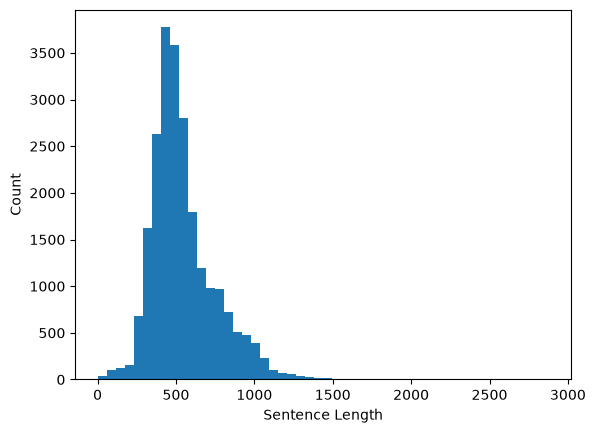

In [25]:
import matplotlib.pyplot as plt

plt.hist(df["roman_length"], bins=50)

plt.xlabel("Sentence Length")

plt.ylabel("Count")

plt.show()

In [26]:
# 1. Keep only relevant columns and drop exact duplicate rows
df_clean = df[["telugu", "roman_telugu"]].drop_duplicates()

# 2. Group the clean data (requires much less RAM)
grouped = df_clean.groupby("telugu")["roman_telugu"].apply(list)


In [27]:
# grouped = df.groupby("telugu")["roman_telugu"].unique()
print(grouped)
print(len(grouped))

telugu
" 'అమ్మా!' అని పిలిపించుకోని జన్మ ఎందుకండీ....నాకోసం ఊరుకోండి. నాకేం కాదు! కోదండరాముడే కాపాడతాడు!" అంది. భార్య పట్టుదల ముందు సుబ్బారాయుడి నిర్ణయం వీగిపోయింది. ఆ రోజునుండి ఆమెకి నొప్పులొచ్చేదాకా ఎన్నెన్ని సంతర్పణలు చేయించాడో, ఏయే యాత్రలు చేసొచ్చాడో లెక్కలేదు. వారి పుణ్యం పండి అలా అపురూపంగా పుట్టిన పిల్లే రాధ! ఆమె బోర్లాపడితే ఇంటిల్లిపాదీ బూరెల గంపలో పడినట్లు పొంగిపోయారు. 'ఉంగా....' అంటే గింగిరాలు తిరిగిపోయారు. చిట్టిపొట్టి అడుగులేస్తే సిరినట్టింట్లో తిరుగుతున్నట్లు ఊహించుకుని సంబరపడిపోయారు. వయసొచ్చి కొబ్బరి మట్టమీద కూర్చున్నప్పుడు ఊరందర్నీ మూడురోజులు పొయ్యి వెలిగించనీయకుండా విందులు చేశారు. ఇప్పుడు పద్దెనిమిదేళ్ళు వచ్చిన రాధ ఎక్కుపెట్టిన మన్మథుడి విల్లులా ఉంటుంది. సొగసులో గులాబీ, ఒద్దికలో చేమంతి, మంచితనంలో మల్లె, ముగ్ధత్వంలో ముద్దబంతితో తులతూగే అందం ఆమెది. గుమ్మడి పాదులాంటి ఉమ్మడికుటుంబంలో అందరికీ ఆమె కనుపాప! ఆ కంట్లో నలకపడితే ఇంటిల్లిపాది కళ్ళూ చెమ్మగిల్లుతాయి. ఆ కాల్లో ముల్లు గుచ్చుకుంటే ఒకరిని మార్చి ఒకరు ఎత్తుకు తిప్పడానికి సిద్దమైపోతారు. ఆమెకి ఒంట్లో నలతగా ఉంటే పాలేర్లూ, పనిమ

In [28]:
# Convert to a DataFrame and save
# grouped_df = grouped.reset_index()
# grouped_df.to_csv("grouped_telugu_data.csv", index=False)


In [29]:
print(df_clean.head())


                                              telugu  \
0  సుశీలమ్మ కళ్ళలో భయం పారాడింది. "అనాధ బిడ్డ అని...   
1  8. దశరథుని మరణము పశ్చాత్తాపముతో కుమిలిపోవుచున్...   
2  "ఎలా వుంది ఫ్రెండ్..... " "టప్ టపా టప్" దూరంగా...   
3  "అది ఊరుకున్నా మీరు వుండలేరు. మీరిద్దరే వుండండ...   
4  అయన అలా వెళ్ళిపోగానే గుమ్మం పక్కనుంచి రాజు బయట...   

                                        roman_telugu  
0  susheelamma kallalo bhayam paaraadindi. "anaad...  
1  8. dasarathuni maranamu paschaattaapamutoe kum...  
2  "ela vundi frend..... " "tup tapa tup" dooramg...  
3  "adhi oorukunnaa meeru vundaleru. meeriddare v...  
4  ayana alaa vellipogaane gummam pakkanunchi raj...  


In [30]:
# print(grouped.to_dict())


In [31]:
word = "nenu"

rows = df[df["roman_telugu"].str.contains(word, case=False)]

print(rows.head(20))

                                               telugu  \
0   సుశీలమ్మ కళ్ళలో భయం పారాడింది. "అనాధ బిడ్డ అని...   
1   8. దశరథుని మరణము పశ్చాత్తాపముతో కుమిలిపోవుచున్...   
3   "అది ఊరుకున్నా మీరు వుండలేరు. మీరిద్దరే వుండండ...   
5   "ఎందుకొచ్చావ్ లోపలికి?" అన్నాడు పరుషంగా. తాపిగ...   
6   నీకు మాటిచ్చాను. ఆమాట కోసం నా ఉద్యోగమే కాదు. ప...   
7   ఫీల్డ్ మార్షల్ సర్వాధికారి, అతని భార్య చతుర, క...   
8   "నేనంతకాలం ఇల్లు పట్టకుండా తిరిగినా, బాధ్యత లే...   
9   18-6-88 శ్రీ రఘుగారికి , నమస్తే, మీరు ప్రేమతో ...   
10  బ్రతకాలి, నాకు మిగిలిందింకా ఒకటి వుంది. "పగ!" ...   
11  "శివశివా..." అన్నారు రాంపండూ, బ్రహ్మాజీ. ఇన్స్...   
12  "మధ్యాహ్నం భోజనానికి ఇంటికొస్తావా" అడిగిందావిడ...   
13  లక్కతో బొట్లు పెట్టివున్న పెద్ద మండిగం దాటి మె...   
15  "ఎవరదీ?" అంది, ద్వారం దగ్గర నిలబడిన సంధ్యని చూ...   
16  పది నిమిషాల తరువాత వచ్చాడు జాకీ. ఆ వెనుకే ట్రై...   
17  తను తొందరపాటుతోనూ, పెంకితనంతోనూ ప్రవర్తించి వు...   
18  "ఏమిటి! ఇందూ" అన్నాడు కంగారుగా. ఇంద్రసేన కళ్ళమ...   
19  అందమైన అపశృతి -కురుమద్దాలి 

In [32]:
from collections import Counter
telugu_counter = Counter()
roman_telugu_counter = Counter()

for telugu, roman in zip(df['telugu'], df['roman_telugu']):
    telugu_counter.update(telugu.split())
    roman_telugu_counter.update(roman.split())

print("Telugu Vocabulary Size:", len(telugu_counter))
print("Roman Telugu Vocabulary Size:", len(roman_telugu_counter))
print(telugu_counter.most_common(20))
print(roman_telugu_counter.most_common(20))

Telugu Vocabulary Size: 1710017
Roman Telugu Vocabulary Size: 1647820
[('ఆ', 137199), ('ఈ', 70540), ('ఆమె', 59651), ('అని', 53595), ('నా', 52391), ('నేను', 46962), ('*', 46615), ('తన', 46326), ('కూడా', 45583), ('అన్నాడు', 43271), ('-', 40186), ('ఒక', 38395), ('నీ', 32895), ('నాకు', 29683), ('అతని', 29531), ('ఓ', 28773), ('మీ', 28103), ('చాలా', 27912), ('అంది', 27445), ('లో', 25327)]
[('aa', 137366), ('ee', 70561), ('aame', 59929), ('ani', 53598), ('naa', 52611), ('nenu', 46967), ('*', 46615), ('tana', 46326), ('kuudaa', 45585), ('annadu', 43301), ('-', 40187), ('oka', 38407), ('nee', 35047), ('naaku', 29693), ('athani', 29532), ('oo', 28970), ('mee', 28474), ('chala', 27918), ('andi', 27459), ('loo', 25327)]


In [33]:
lengths = []

for roman, telugu in zip(df['telugu'], df['roman_telugu']):
    lengths.append(len(roman.split()))

print("Average length:", sum(lengths) / len(lengths))
print("Maximum length:", max(lengths))
print("Minimum length:", min(lengths))

Average length: 547.005696038664
Maximum length: 2877
Minimum length: 1


In [34]:
import re

def split_sentences(text):
    sentences = re.split(r'[.!?]+', text)

    sentences = [s.strip() for s in sentences]

    sentences = [s for s in sentences if len(s) > 0]

    return sentences

In [35]:
roman, telugu = df['roman_telugu'][0], df['telugu'][0]
roman_sentences = split_sentences(roman)

telugu_sentences = split_sentences(telugu)

print(len(roman_sentences))
print(len(telugu_sentences))

78
78


In [36]:
print(roman_sentences)

['susheelamma kallalo bhayam paaraadindi', '"anaadha bidda ani chinnappude teliste mana daggiravaadu alaa aramarika lekunda chanuvugaa perigevada', '" puttedu digulu susheelamma kanthamlo palikindi', '"adhi manam penchedaanni batti vuntundi', 'atuvanti bedhaalu manalo lenattu telusukonela penchaali', '" "chaalaamandi alaage penchutaaru gadandii', '" "enado okanadu aa vishayam teliyakapodu', 'manam patnamlo vuntunnam ganaka yinta kalamayina ee rahasyaanni dachagaligam', 'susheelamma vintuu koorchundi', '"oka vyaktitvam antuu erpaddaka aa rahasyam teliste lothugaa gaayapadataaru', 'aneka aalochanalu vastaayi', 'chinnappude teliste antagaa talakrindulai poru" annadu', '"vaadu manalni vadilesi vellipotademo', '" analeka antunna aame gontulo edho addupadinattu ukkiribikkiri ayipotundi', 'ramanathaniki kuudaa aa bhayam lekapoledu', 'aa bhayanni daachukuntuu velladu', 'ela velataadu', 'ekkadiki velataadu', 'asalu enduku vellaali', 'vaadiki manamem takkuva chesamani veltaadu', '" annadu', 'sus

In [37]:
for i, (r, t) in enumerate(zip(roman_sentences, telugu_sentences)):
    print("="*60)
    print(i)
    print(r)
    print(t)

0
susheelamma kallalo bhayam paaraadindi
సుశీలమ్మ కళ్ళలో భయం పారాడింది
1
"anaadha bidda ani chinnappude teliste mana daggiravaadu alaa aramarika lekunda chanuvugaa perigevada
"అనాధ బిడ్డ అని చిన్నప్పుడే తెలిస్తే మన దగ్గిరవాడు అలా అరమరిక లేకుండా చనువుగా పెరిగేవాడా
2
" puttedu digulu susheelamma kanthamlo palikindi
" పుట్టెడు దిగులు సుశీలమ్మ కంఠంలో పలికింది
3
"adhi manam penchedaanni batti vuntundi
"అది మనం పెంచేదాన్ని బట్టి వుంటుంది
4
atuvanti bedhaalu manalo lenattu telusukonela penchaali
అటువంటి బేధాలు మనలో లేనట్టు తెలుసుకొనేలా పెంచాలి
5
" "chaalaamandi alaage penchutaaru gadandii
" "చాలామంది అలాగే పెంచుతారు గదండీ
6
" "enado okanadu aa vishayam teliyakapodu
" "ఏనాడో ఒకనాడు ఆ విషయం తెలియకపోదు
7
manam patnamlo vuntunnam ganaka yinta kalamayina ee rahasyaanni dachagaligam
మనం పట్నంలో వుంటున్నాం గనక యింత కాలమయినా ఈ రహస్యాన్ని దాచగలిగాం
8
susheelamma vintuu koorchundi
సుశీలమ్మ వింటూ కూర్చుంది
9
"oka vyaktitvam antuu erpaddaka aa rahasyam teliste lothugaa gaayapadataaru
"ఒక వ్యక్తిత్వం అంటూ

In [38]:
count_equal = 0
count_unequal = 0

for roman, telugu in zip(df['roman_telugu'], df['telugu']):

    r = split_sentences(roman)
    t = split_sentences(telugu)

    if len(r) == len(t):
        count_equal += 1
    else:
        count_unequal += 1

print("Equal :", count_equal)
print("Unequal :", count_unequal)

Equal : 23174
Unequal : 0


In [39]:
lengths = [len(r.split()) for r, _ in sentence_pairs]

print("Average :", sum(lengths)/len(lengths))
print("Maximum :", max(lengths))
print("Minimum :", min(lengths))

NameError: name 'sentence_pairs' is not defined

In [ ]:
import re

ELLIPSIS = "<ELLIPSIS>"

def normalize_ellipsis(text):

    text = re.sub(r"\.{3,}", f" {ELLIPSIS} ", text)

    return text

In [ ]:
def normalize_quotes(text):

    replacements = {
        "“": '"',
        "”": '"',
        "‘": "'",
        "’": "'",
        "``": '"',
        "''": '"'
    }

    for old, new in replacements.items():
        text = text.replace(old, new)

    return text

In [ ]:
def normalize_quotes(text):

    replacements = {
        "“": '"',
        "”": '"',
        "‘": "'",
        "’": "'",
        "``": '"',
        "''": '"'
    }

    for old, new in replacements.items():
        text = text.replace(old, new)

    return text

In [ ]:
def fix_quotes(text):

    if text.count('"') % 2 == 1:

        if text.startswith('"'):
            text += '"'

        elif text.endswith('"'):
            text = '"' + text

    return text

In [ ]:
def split_sentences(text):

    sentences = []

    current = []

    in_quote = False

    i = 0

    while i < len(text):

        ch = text[i]

        current.append(ch)

        if ch == '"':
            in_quote = not in_quote

        if (ch in ".?!") and (not in_quote):

            sentence = "".join(current).strip()

            if sentence:
                sentences.append(sentence)

            current = []

        i += 1

    if current:

        sentence = "".join(current).strip()

        if sentence:
            sentences.append(sentence)

    return sentences

In [ ]:
def restore_ellipsis(text):

    return text.replace("<ELLIPSIS>", "...")

In [ ]:
def clean_spaces(text):

    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [ ]:
def preprocess(text):

    text = normalize_quotes(text)

    text = normalize_ellipsis(text)

    text = fix_quotes(text)

    text = clean_spaces(text)

    return text

In [ ]:
roman = preprocess(roman)

telugu = preprocess(telugu)

roman_sentences = split_sentences(roman)

telugu_sentences = split_sentences(telugu)

In [ ]:
print(len(roman_sentences))
len(telugu_sentences)


35


35

In [ ]:
sentence_pairs = []

for roman, telugu in zip(df['roman_telugu'], df['telugu']):

    r = split_sentences(roman)
    t = split_sentences(telugu)
    r = preprocess(r)
    t = preprocess(t)
    if len(r) != len(t):
        continue

    for rs, ts in zip(r, t):
        sentence_pairs.append((rs, ts))
print(len(sentence_pairs))

AttributeError: 'list' object has no attribute 'replace'